In [61]:
import phidl
import phidl.geometry as pg
from phidl import quickplot as qp
import numpy as np
import os
from phidl import Device, Path
import phidl.path as pp
from scipy.constants import epsilon_0, mu_0
from scipy.special import ellipk
import phidl.routing as pr

In [62]:
def calculate_segment_length(
    L_len=400,
    radius=200
):
    P = Path()
    direction = -1
    P.append(pp.straight(2*radius))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180*direction))
    P.append(pp.straight(L_len))
    direction *= -1
    P.append(pp.arc(radius=radius, angle=-90*direction))
    return P.length()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


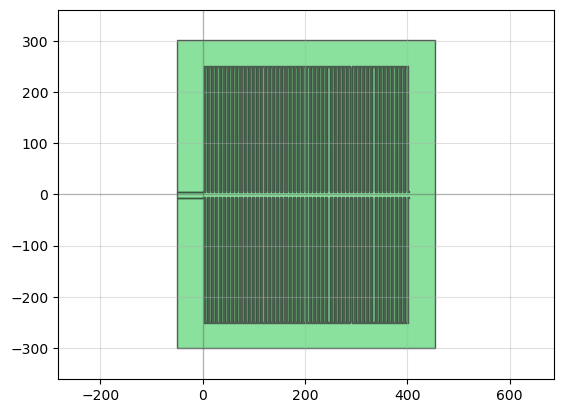

'interdigitated_finger_500um_n50.gds'

In [63]:
import phidl.path as pp
import phidl.geometry as pg
from phidl import Device, quickplot as qp


def digitated_shape(
    N=5,
    finger_width=5,      # extent of each finger along the path (x)
    finger_gap=5,        # path length of each bus-only section (x)
    finger_length=100,   # transverse extent of each finger section (y)
    bus_width=5,         # transverse width of the gap sections (y)
    ground_plane=10,     # border distance of the outline
    layer=0,
    outline_layer=1,
    precision=1e-6,
):
    # Total path length: N finger widths + (N+1) gaps
    total_length = N * finger_width + (N + 1) * finger_gap

    # Section sequence: gap, finger, gap, finger, ..., gap
    lengths, widths = [], []
    for _ in range(N):
        lengths += [finger_gap, finger_width]
        widths += [bus_width, finger_length]
    lengths.append(finger_gap)
    widths.append(bus_width)
    assert abs(sum(lengths) - total_length) < 1e-9

    # Extrude each section with its own constant width and place it along x
    segs = Device("segments")
    x = 0
    for L, w in zip(lengths, widths):
        P = pp.straight(length=L, num_pts=2)
        ref = segs << P.extrude(width=w, layer=layer)
        ref.movex(x)
        x += L

    # Merge into one polygon and add ports at the two bus ends
    shape = pg.union(segs, precision=precision, layer=layer)
    shape.add_port(name=1, midpoint=(0, 0), width=bus_width, orientation=180)
    shape.add_port(name=2, midpoint=(total_length, 0), width=bus_width, orientation=0)

    # Outline with a border of `ground_plane`, cut open at the ports
    border = pg.outline(
        shape,
        distance=ground_plane,
        open_ports=1000,
        precision=precision,
        layer=outline_layer,
    )

    return border

shape = digitated_shape(
    N=50,
    finger_width=4,      
    finger_gap=4,        
    finger_length=500,   
    bus_width=10,         
    ground_plane=1,     
    layer=0,
    outline_layer=0
)

padding = 50
b = shape.bbox
padded_bbox = [
    [b[0][0]-padding, b[0][1] - padding],
    [b[1][0]+padding, b[1][1] + padding],
]
gp = pg.bbox(padded_bbox)

chip = pg.boolean(gp,shape,operation='A-B')

qp(chip)
chip.write_gds("interdigitated_finger_500um_n50.gds")

In [64]:
def make_nanowire(
    L_len=300,
    radius=150,
    width=2,
    center_pin_length=7000,
    center_pin_gap = 60,
):

    P = Path()
    direction = -1
    P.append(pp.arc(radius=radius, angle=90 * direction))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180 * direction))
    P.append(pp.straight(L_len))
    add_length = calculate_segment_length(L_len=L_len,radius=radius)
    total_length = P.length()
    while total_length < (center_pin_length-add_length):

        P.append(pp.straight(2*radius))
        P.append(pp.straight(L_len))
        P.append(pp.arc(radius=radius, angle=180 * direction))
        P.append(pp.straight(L_len))
        direction *= -1
        total_length = P.length()

    P.append(pp.arc(radius=radius, angle=90 * direction))
    total_length = P.length()

    remaining_len = center_pin_length - P.length()
    if remaining_len < 0:
        print("ERROR! NEGATIVE LENGTH!")

    P = pp.straight(remaining_len/2).append(P)
    P = P.append(pp.straight(remaining_len/2))

    print(P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    coupled_nanowire = D

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    coupled_nanowire_outline = D

    return coupled_nanowire, coupled_nanowire_outline

In [65]:
def smooth_device(r,smoothing_radius=2):
    r_round = phidl.Device("round_r")
    for port in r.ports.values():
        r_round.add_port(port)
    dev = pg.union(r, precision=1e-6, layer=0)   # instead of boolean with B=None
    dev.flatten()
    for ps in dev.polygons:
        ps.fillet(radius=smoothing_radius)
        for pts in ps.polygons:          # a PolygonSet can hold several polygons
            r_round.add_polygon(pts, layer=0)
    return r_round

In [66]:
def make_capacitor(
        width,
        length,
        gap
):
        P = Path()
        P.append(pp.straight(length))
        D = Device('meander')
        X = phidl.CrossSection()
        X.add(width = width, ports = (1,2))
        D << P.extrude(X)
        D.add_port(D.references[0].ports[1])
        D.add_port(D.references[0].ports[2])

        cap = D

        P = Path()
        P.append(pp.straight(length+2*gap))
        D = Device('meander')
        X = phidl.CrossSection()
        X.add(width = width+2*gap, ports = (1,2))
        D << P.extrude(X)
        D.add_port(D.references[0].ports[1])
        D.add_port(D.references[0].ports[2])

        cap_outline = D

        return cap, cap_outline

900.0


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


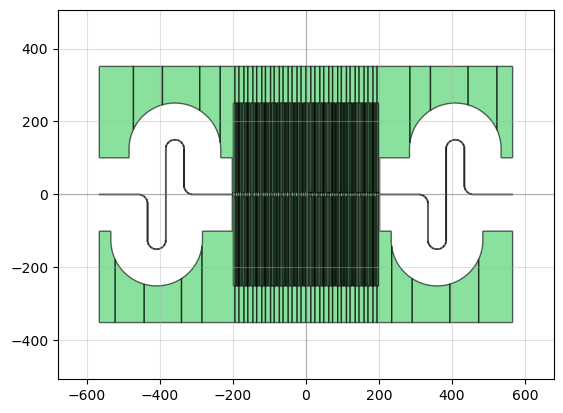

'102426.gds'

In [70]:
cap, cap_outline = make_capacitor(
    width = 500,
    length = 500,
    gap = 4)

nanowire, nanowire_outline = make_nanowire(
    L_len=100,
    radius=25,
    width=1,
    center_pin_length=900,
    center_pin_gap = 100
)

filter = phidl.Device('filter')

smooth = True
if smooth:
    cap = smooth_device(cap)

wire1_outline = filter.add_ref(nanowire_outline)
wire2_outline = filter.add_ref(nanowire_outline)
cap1_outline = filter.add_ref(shape)
cap1_outline.x=0

wire1_outline.connect(2,cap1_outline.ports[1])
wire2_outline.connect(1,cap1_outline.ports[2])

padding = 100
b = filter.bbox
padded_bbox = [
    [b[0][0], b[0][1] - padding],
    [b[1][0], b[1][1] + padding],
]
gp = pg.bbox(padded_bbox)

gp = filter.add_ref(gp)

filter = pg.boolean(filter,wire1_outline,operation='A-B')
filter = pg.boolean(filter,wire2_outline,operation='A-B')
filter = pg.boolean(filter,cap1_outline,operation='A-B') 

# filter = smooth_device(filter)

wire1 = filter.add_ref(nanowire)
wire2 = filter.add_ref(nanowire)

wire1.x = wire1_outline.x
wire2.x = wire2_outline.x

filter = smooth_device(filter)

qp(filter)
filter.write_gds('102426.gds')

In [10]:
# Define resonators for WTe2 DC chip.
def make_lamda2_res_meander(
    L_len=300,
    radius=150,
    width=2,
    center_pin_length=7000,
    center_pin_gap = 60,
    coupling_length = 20,
    coupling_width=5,
    space=100,
    hammerhead_gap=2
):

    P = Path()
    direction = -1
    P.append(pp.arc(radius=radius, angle=90 * direction))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180 * direction))
    P.append(pp.straight(L_len))
    add_length = calculate_segment_length(L_len=L_len,radius=radius)
    total_length = P.length()
    while total_length < (center_pin_length-add_length):

        P.append(pp.straight(2*radius))
        P.append(pp.straight(L_len))
        P.append(pp.arc(radius=radius, angle=180 * direction))
        P.append(pp.straight(L_len))
        direction *= -1
        total_length = P.length()

    P.append(pp.arc(radius=radius, angle=90 * direction))
    total_length = P.length()

    remaining_len = center_pin_length - P.length()
    if remaining_len < 0:
        print("ERROR! NEGATIVE LENGTH!")

    P = pp.straight(remaining_len/2).append(P)
    P = P.append(pp.straight(remaining_len/2))

    print(P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])
    
    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    hh_ref2 = coupled_resonator.add_ref(hammerhead)
    hh_ref2.connect(1,resonator_ref.ports[2])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])
    coupled_resonator.add_port(hh_ref2.ports[2])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])
    hh_ref2 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref2.connect(1,ref_D_outline.ports[2])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    coupled_resonator_outline.add_port(hh_ref2.ports[2])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

In [8]:
def make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width):
    
    pad = pg.taper(length=pad_size,width1=pad_size,width2=pad_size)
    taper = pg.taper(length=taper_len,width1=pad_size,width2=feedline_width)
    feedline = pg.taper(length=feedline_len,width1=feedline_width,width2=feedline_width)

    feedline_dev = phidl.Device("feedline")
    pad_ref1 = feedline_dev.add_ref(pad)
    taper_ref1 = feedline_dev.add_ref(taper)
    feedline_ref = feedline_dev.add_ref(feedline)
    taper_ref1.connect(1,destination=pad_ref1.ports[2])
    feedline_ref.connect(1,destination=taper_ref1.ports[2])
    taper_ref2 = feedline_dev.add_ref(taper)
    pad_ref2 = feedline_dev.add_ref(pad)
    taper_ref2.connect(2,destination=feedline_ref.ports[2])
    pad_ref2.connect(2,destination=taper_ref2.ports[1])
    feedline_dev.xmax = 0

    return feedline_dev

def make_feedline_contact(
    pad_size = 200,
    taper_len = 100,
    feedline_len = 0,
    feedline_width = 66,
    ground_gap = 2,
):
    """
    TODO: Add ports to couple resonator to!
    """
    feedline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline.x = 0

    pad_size += 100
    feedline_width += 2*ground_gap

    feedline_outline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline_outline.x = 0

    return feedline, feedline_outline

In [9]:
# Define two NbN hallbars on the chip.
current, current_outline = make_feedline_contact(    
    pad_size = 250,
    taper_len = 50,
    feedline_len = 800,
    feedline_width = 100,
    ground_gap = 25
    )

voltage, voltage_outline = make_feedline_contact(    
    pad_size = 250,
    taper_len = 50,
    feedline_len = 400,
    feedline_width = 10,
    ground_gap = 25
    )

def make_hallbar(current,voltage1):

    hallbar = phidl.Device('hallbar')
    current_ref = hallbar.add_ref(current)
    current_ref.x=0

    voltage_ref1 = hallbar.add_ref(voltage1)
    voltage_ref1.rotate(90)
    voltage_ref1.y = 0
    voltage_ref1.x = -750/3

    voltage_ref2 = hallbar.add_ref(voltage1)
    voltage_ref2.rotate(90)
    voltage_ref2.y = 0
    voltage_ref2.x = 750/3

    return hallbar

In [15]:
resonator_params = [(2,80,2,60,3500,50)]

common_params = dict(
    L_len=350,
    radius=200,
    coupling_width=20
)

resonators = []
outlines = []
for (hammerhead_gap,hammerhead_width,width,center_pin_gap,center_pin_length,coupling_length) in resonator_params:
    res, outline = make_lamda2_res_meander(hammerhead_gap=hammerhead_gap, coupling_length = hammerhead_width,width=width, center_pin_gap=center_pin_gap, center_pin_length=center_pin_length,**common_params)
    resonators.append(res)
    outlines.append(outline)

pad_size = 250
taper_len = 100
feedline_len = 7000
feedline_width = 80
ground_gap = 4

groundplane = pg.rectangle(size=(10e3,10e3))

feedline, feedline_outline = make_feedline_contact(    
    pad_size = pad_size,
    taper_len = taper_len,
    feedline_len = feedline_len,
    feedline_width = feedline_width,
    ground_gap = ground_gap
    )

feedline.add_port(0,midpoint=(0,feedline_width/2),orientation=90)
feedline.add_port(3,midpoint=(-feedline_len/3,-feedline_width/2),orientation=-90)
feedline.add_port(5,midpoint=(feedline_len/3,-feedline_width/2),orientation=-90)

3500.0


Port (name 5, midpoint [2333.33333333  -40.        ], width 1, orientation 270)

In [ ]:
smooth = True

chip_layout = phidl.Device('chip_layout')
groundplane_ref = chip_layout.add_ref(groundplane)
groundplane_ref.x=0
groundplane_ref.y=0

if smooth:
    feedline = smooth_device(feedline)
    feedline_outline = smooth_device(feedline_outline)
    resonators = [smooth_device(res) for res in resonators]
    outlines = [smooth_device(outline) for outline in outlines]

# Subtract the ground plane gaps.
feedline_ref = chip_layout.add_ref(feedline)
feedline_outline_ref = chip_layout.add_ref(feedline_outline)

feedline_ref.y = 1000
feedline_outline_ref.y = 1000

# Add feedline.
chip_layout = pg.boolean(chip_layout,feedline_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,feedline_ref,operation='A+B')

res = resonators[i]
res_outline = outlines[i]
hammerhead_gap = hammerhead_gaps[i]
res_ref = chip_layout.add_ref(res)
res_outline_ref = chip_layout.add_ref(res_outline)
port = feedline_ref.ports[i]

res_outline_ref.x = port.midpoint[0]
res_outline_ref.ymin = port.midpoint[1] 

res_ref.x = port.midpoint[0]
res_ref.ymin = port.midpoint[1] + hammerhead_gap

chip_layout = pg.boolean(chip_layout,res_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,res_ref,operation='A+B')

for (x,y) in [(0,-3500),(3000,-3500),(-3000,-3500)]:

    hallbar = make_hallbar(current,voltage)
    hallbar_outline = make_hallbar(current_outline,voltage_outline)

    hallbar_ref = chip_layout.add_ref(hallbar)
    hallbar_outline_ref = chip_layout.add_ref(hallbar_outline)

    hallbar_ref.x = x
    hallbar_ref.y = y
    hallbar_outline_ref.x = x
    hallbar_outline_ref.y = y

    chip_layout = pg.boolean(chip_layout,hallbar_outline_ref,operation='A-B')
    chip_layout = pg.boolean(chip_layout,hallbar_ref,operation='A+B')

# marker_locs = [(1200,1200)]
# for marker_loc in marker_locs:
#     for xmag in [-1,1]:
#         for ymag in [0,-1,1,-2,2,-3,3]:
#             xloc = xmag*marker_loc[0]
#             yloc = ymag*marker_loc[1]
#             marker_ref = chip_layout.add_ref(marker)
#             center_marker_ref = chip_layout.add_ref(center_marker)
#             marker_ref.x = xloc
#             marker_ref.y = yloc
#             center_marker_ref.x = xloc
#             center_marker_ref.y = yloc
#             chip_layout = pg.boolean(chip_layout,marker_ref,operation='A-B')
#             chip_layout = pg.boolean(chip_layout,center_marker_ref,operation='A+B')

qp(chip_layout)
chip_layout.write_gds('nbn_res_chip.gds')

NameError: name 'hammerhead_gaps' is not defined